# 02 — Alignment, Cleaning & Returns

**Phase 2/7 — Cleaning, alignment & returns.** Data mentah dari Phase 1 diubah jadi return yang siap dianalisis. Bad tick FX dibuang dengan aturan yang sudah dikunci (README poin 4 + Amandemen 1). Gerakan besar di indeks, ETF, komoditas, dan sentimen hanya ditandai (poin 8). Setiap seri dipasangkan dengan IHSG hanya di tanggal yang **sama-sama buka**, tanpa forward-fill, karena forward-fill menciptakan return nol palsu yang mengecilkan korelasi.

Notebook ini juga menjalankan **uji ulang USD/IDR** dengan aturan yang dikunci sebelum cleaning. Hasilnya menentukan apakah rupiah menjadi driver atau permanen alat bantu.

Input: `reports/phase1/decisions.json` dan `config/tickers.yaml`. Semua logika ada di `src/preprocess.py`.

In [1]:
import json

import pandas as pd
from IPython.display import Markdown, display

from src import plots
from src import preprocess as pp
from src import quality as q
from src.config import PROJECT_ROOT, load_config, series_table
from src.data_loader import close_panel, load_prices

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

cfg = load_config()
qcfg = cfg["quality"]
series = series_table(cfg, groups=("target", "core", "tools"))
target_id = cfg["project"]["target_id"]
fx_id = cfg["usdidr_retest"]["id"]
transforms = dict(zip(series["id"], series["transform"]))

dec1 = pp.load_phase1_decisions(PROJECT_ROOT / "reports" / "phase1" / "decisions.json")
print(f"Periode analisis: {dec1['analysis_start']} | return_mode: {dec1['return_mode']} (tidak ada pemecahan gap/intraday)")

Periode analisis: 2007-01-01 | return_mode: close_to_close (tidak ada pemecahan gap/intraday)


## 1. Data

Memakai cache Phase 1 di `data/raw/`. Kalau cache sudah lebih dari 7 hari, data didownload ulang, sehingga angka di bawah bisa sedikit berbeda dari laporan Phase 1.

In [2]:
prices = load_prices(series["ticker"].tolist(), start=dec1["analysis_start"], end=cfg["project"]["end_date"])
raw = close_panel(prices, dict(zip(series["ticker"], series["id"])))
print(f"Panel mentah: {raw.shape[0]:,} tanggal x {raw.shape[1]} seri, {raw.index.min():%d %b %Y} s/d {raw.index.max():%d %b %Y}")

Cache: 12 | Download baru: 0 | Gagal: 0
Panel mentah: 5,168 tanggal x 12 seri, 01 Jan 2007 s/d 21 Oct 2026


## 2. Cleaning

Aturannya:
- **^JKSE:** hari suspend BEI (9–10 Okt 2008) dan baris basi (Close = Close kemarin **dan** Volume 0) diperlakukan sebagai hari libur.
- **FX:** bad tick = |log return| > 5% yang dibalik minimal 50% ke arah sebaliknya **dalam ≤ 5 hari bursa** (Amandemen 1, mengikat). Harga dari hari lonjakan sampai sehari sebelum pembalikan dijadikan kosong. Aturan ini generik untuk semua seri berkategori `fx`.
- **Kategori lain:** tidak ada yang dibuang.

In [3]:
clean, cleaning_log, stale_flags = pp.clean_prices(prices, series, cfg)
clean_old, log_old, _ = pp.clean_prices(prices, series, cfg, fx_max_days=qcfg["fx_cleaning"]["max_reversal_days_old"])

display(cleaning_log.groupby(["id", "reason"]).size().to_frame("hari dibuang"))
cleaning_log.round({"close": 2, "entry_ret": 4, "reversal_ret": 4})

,,hari dibuang
id,reason,
JKSE,"baris basi (Close = kemarin, Volume 0) -> libur",1
USDIDR,bad tick FX (pembalikan <= 5 hari bursa),13


,id,ticker,Date,close,reason,entry_date,reversal_date,entry_ret,reversal_ret,run_days
0,JKSE,^JKSE,2017-12-01,5952.14,"baris basi (Close = kemarin, Volume 0) -> libur",NaT,NaT,NaN,NaN,NaN
1,USDIDR,IDR=X,2010-11-01,888.11,bad tick FX (pembalikan <= 5 hari bursa),2010-11-01,2010-11-02,-2.3074,2.3055,1.0
2,USDIDR,IDR=X,2012-02-07,892.00,bad tick FX (pembalikan <= 5 hari bursa),2012-02-07,2012-02-08,-2.3035,2.3037,1.0
3,USDIDR,IDR=X,2013-10-14,10787.00,bad tick FX (pembalikan <= 5 hari bursa),2013-10-14,2013-10-15,-0.0608,0.0497,1.0
4,USDIDR,IDR=X,2013-10-28,9612.45,bad tick FX (pembalikan <= 5 hari bursa),2013-10-28,2013-10-29,-0.1464,0.1371,1.0
5,USDIDR,IDR=X,2013-11-11,9612.45,bad tick FX (pembalikan <= 5 hari bursa),2013-11-11,2013-11-12,-0.1673,0.1821,1.0
6,USDIDR,IDR=X,2013-11-18,9612.45,bad tick FX (pembalikan <= 5 hari bursa),2013-11-18,2013-11-19,-0.1806,0.1884,1.0
7,USDIDR,IDR=X,2013-11-25,9612.45,bad tick FX (pembalikan <= 5 hari bursa),2013-11-25,2013-11-26,-0.1943,0.1982,1.0
8,USDIDR,IDR=X,2013-11-29,9612.45,bad tick FX (pembalikan <= 5 hari bursa),2013-11-29,2013-12-04,-0.2118,0.2122,3.0
9,USDIDR,IDR=X,2013-12-02,9612.45,bad tick FX (pembalikan <= 5 hari bursa),2013-11-29,2013-12-04,-0.2118,0.2122,3.0


In [4]:
# Hari yang dibuang Amandemen 1 tetapi lolos dari aturan lama
extra = sorted(set(cleaning_log.loc[cleaning_log["id"] == fx_id, "Date"]) - set(log_old.loc[log_old["id"] == fx_id, "Date"]))
print(f"Aturan lama: {int((log_old['id'] == fx_id).sum())} hari | Amandemen 1: {int((cleaning_log['id'] == fx_id).sum())} hari")
print("Tambahan Amandemen 1:", [f"{d:%Y-%m-%d} ({d:%a})" for d in extra])

Aturan lama: 8 hari | Amandemen 1: 13 hari
Tambahan Amandemen 1: ['2013-11-29 (Fri)', '2013-12-02 (Mon)', '2013-12-03 (Tue)', '2013-12-06 (Fri)', '2013-12-09 (Mon)']


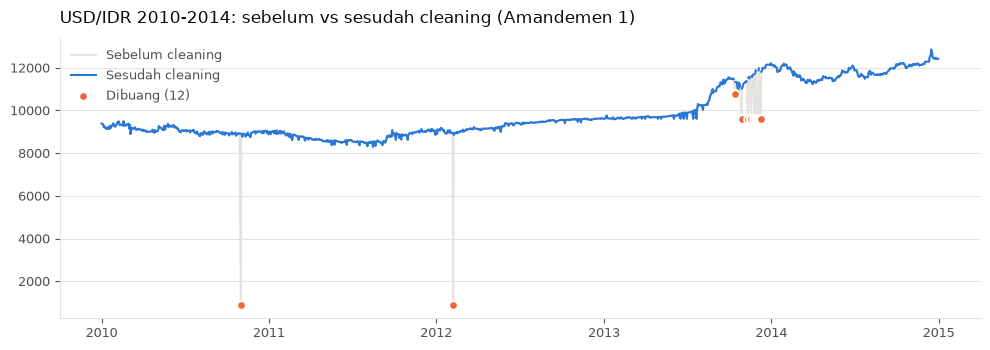

In [5]:
fig = plots.plot_fx_cleaning(raw[fx_id], clean[fx_id], "USD/IDR 2010-2014: sebelum vs sesudah cleaning (Amandemen 1)",
                             "2010-01-01", "2014-12-31")

### Gerakan besar non-FX (hanya ditandai)

Sesuai README poin 8, gerakan besar di indeks, ETF, komoditas, dan sentimen **tidak dibuang**. Di Phase 1 semuanya jatuh di episode krisis (2008, 2020, 2025, 2026) dan tampak nyata.

In [6]:
moves = q.moves_table(prices, series, qcfg)
moves_other = moves[moves["category"] != "fx"].reset_index(drop=True)
moves_other.round({"ret": 4, "next_ret": 4})

,id,category,Date,ret,next_ret,bad_tick
0,BRENT,commodity,2020-03-09,-0.2758,0.0800,False
1,BRENT,commodity,2020-04-21,-0.2798,0.0524,False
2,COPPER,commodity,2025-07-31,-0.2517,0.0188,False
3,EEM,etf,2008-09-29,-0.1242,0.0779,True
4,EEM,etf,2008-10-13,0.2051,-0.0510,False
5,EEM,etf,2008-10-15,-0.1763,0.0480,False
6,EEM,etf,2008-10-28,0.1901,-0.0322,False
7,EEM,etf,2008-10-30,0.1266,-0.0086,False
8,EEM,etf,2008-11-05,-0.1361,-0.0517,False
9,EEM,etf,2008-11-13,0.1297,-0.1009,True


## 3. Kuotasi basi USD/IDR (hanya ditandai)

Harga yang persis berulang ≥ 10 kali (nilai basi 9.612,45) dan harga dalam ±0,05% darinya **tidak dibuang**. Harga ini ditandai di kolom `flag_stale_quote` pada panel harian, dan cara menanganinya diputuskan sebelum Phase 4.

Pengecekan penting: berapa harga yang ditandai jatuh di **harga mingguan** (harga terakhir tiap minggu)? Kalau nol, uji ulang mingguan tidak terpengaruh.

In [7]:
flagged = clean.loc[stale_flags[fx_id], [fx_id]].assign(hari=lambda d: d.index.day_name())
week_last = clean[fx_id].dropna().groupby(pd.Grouper(freq="W-FRI")).tail(1).index
flagged["harga_mingguan"] = flagged.index.isin(week_last)
win = cfg["project"]["screening_window"]
weekly_flagged = int(flagged.loc[win[0]:win[1], "harga_mingguan"].sum())
print(f"{len(flagged)} hari ditandai ({(flagged['hari'] == 'Monday').sum()} hari Senin); "
      f"jadi harga mingguan di {win[0][:4]}-{win[1][:4]}: {weekly_flagged}")
flagged

25 hari ditandai (21 hari Senin); jadi harga mingguan di 2010-2019: 0


,USDIDR,hari,harga_mingguan
Date,,,
2012-11-26,9612.450195,Monday,False
2012-12-10,9612.450195,Monday,False
2012-12-17,9612.450195,Monday,False
2012-12-18,9611.799805,Tuesday,False
2012-12-19,9615.700195,Wednesday,False
2012-12-24,9610.000000,Monday,False
2012-12-31,9612.450195,Monday,False
2013-01-01,9609.000000,Tuesday,False
2013-01-02,9609.000000,Wednesday,False


## 4. Uji ulang USD/IDR

Aturan (README poin 4, dikunci sebelum cleaning):
- **Ukuran:** |Pearson| log return mingguan (W-FRI) USD/IDR vs IHSG, metode sama dengan `scripts/screening.py`.
- **Periode:** 2010–2019.
- **Batas:** |r| ≥ 0,300, dipotong 3 desimal tanpa pembulatan ke atas.

Tiga angka dilaporkan:
1. **Sebelum cleaning:** pembanding dengan screening (−0,19).
2. **Aturan lama** (pembalikan ≤ 1 hari): sensitivitas, **tidak mengikat**.
3. **Amandemen 1** (pembalikan ≤ 5 hari): **MENGIKAT**.

In [8]:
min_abs = cfg["usdidr_retest"]["min_abs_corr"]
variants = {
    "sebelum cleaning": (raw, False),
    "aturan lama (<= 1 hari, sensitivitas)": (clean_old, False),
    "Amandemen 1 (<= 5 hari, MENGIKAT)": (clean, True),
}
retest = pp.usdidr_retest(variants, fx_id, target_id, transforms, win, min_abs)
decision = pp.retest_decision(retest, min_abs, "aturan lama (<= 1 hari, sensitivitas)")
display(retest.round({"r": 4}))
display(Markdown(f"**Keputusan:** {decision['reason']}.  \n{decision['note']}"))

,varian,r,abs_r_3dp,n_minggu,lolos,mengikat
0,sebelum cleaning,-0.1895,0.189,507,False,False
1,"aturan lama (<= 1 hari, sensitivitas)",-0.1895,0.189,507,False,False
2,"Amandemen 1 (<= 5 hari, MENGIKAT)",-0.3340,0.334,507,True,True


**Keputusan:** |r| mingguan 2010-2019 pasca-cleaning (Amandemen 1 (<= 5 hari, MENGIKAT)) = 0.334 (r = -0.3340, 507 minggu), batas 0.300: LOLOS -> driver (Core).  
PERHATIAN: status berbeda dengan aturan lama (0.189 -> tidak lolos).

## 5. Returns

- **Harian:** log return per pasangan IHSG–seri, dihitung hanya di tanggal yang dua-duanya punya harga. `gap_days` = jarak kalender ke tanggal bersama sebelumnya; return setelah libur panjang mencakup beberapa hari bursa.
- **Mingguan:** W-FRI, harga terakhir yang tersedia tiap minggu.
- **IHSG dalam USD** = ^JKSE / USD/IDR (yang sudah dibersihkan), hanya di tanggal yang dua-duanya punya harga. IDR=X ditutup di jam AS, sedangkan IHSG tutup 16:00 WIB, jadi kursnya bukan kurs pada saat IHSG tutup (lihat Keterbatasan data di README).

In [9]:
jkse_usd_id = cfg["jkse_usd"]["id"]
jkse_usd = pp.jkse_in_usd(clean, target_id, cfg["jkse_usd"]["fx_id"], jkse_usd_id)
transforms_all = {**transforms, jkse_usd_id: "log"}

daily = pp.pair_daily_returns(clean, target_id, transforms, stale_flags)
weekly = pp.weekly_returns(clean.join(jkse_usd, how="left"), transforms_all)
coverage = pp.pair_coverage(daily)
coverage

,n_return,mulai,akhir,pct_gap_gt4,n_flag_stale
id,,,,,
BRENT,4477,2007-07-31,2026-10-21,1.83,0
COPPER,4666,2007-01-03,2026-10-21,1.61,0
EEM,4665,2007-01-04,2026-10-20,1.61,0
EIDO,3878,2010-05-10,2026-10-20,1.47,0
HSI,4594,2007-01-03,2026-10-21,2.26,0
KLCI,4631,2007-01-04,2026-10-21,1.88,0
NIFTY,4400,2007-09-18,2026-10-21,1.93,0
SPX,4665,2007-01-04,2026-10-20,1.61,0
STI,4703,2007-01-04,2026-10-21,1.70,0


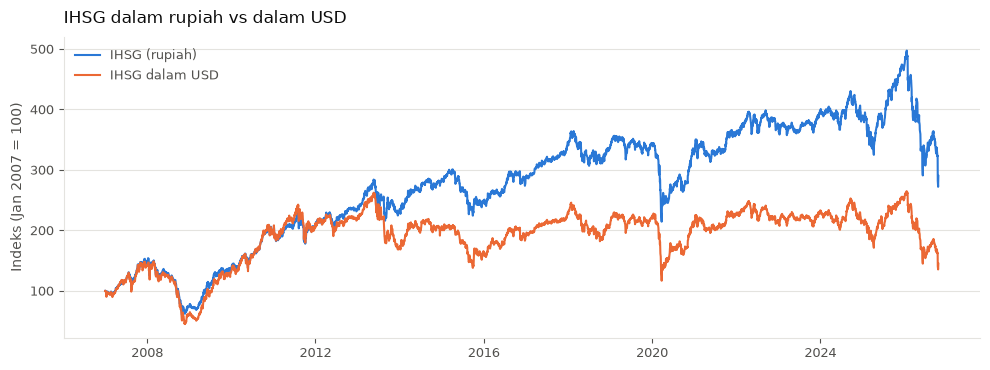

In [10]:
fig = plots.plot_idr_vs_usd(clean[target_id], jkse_usd, "IHSG dalam rupiah vs dalam USD")

## 6. Simpan hasil

Panel besar (parquet) disimpan ke `data/processed/` dan tidak di-commit. Ringkasan kecil disimpan ke `reports/phase2/` dan di-commit.

In [11]:
processed = pp.save_processed(PROJECT_ROOT / "data" / "processed", {
    "prices_clean": clean, "stale_quote_flags": stale_flags, "daily_pair_returns": daily,
    "weekly_returns": weekly, "jkse_usd": jkse_usd})
extra_info = {
    "analysis_start": dec1["analysis_start"], "return_mode": dec1["return_mode"],
    "removed_per_series": cleaning_log.groupby("id").size().to_dict(),
    "removed_old_rule_per_series": log_old.groupby("id").size().to_dict(),
    "stale_quote_flagged": {k: int(v) for k, v in stale_flags.sum().items()},
    "stale_quote_weekly_prices_in_window": weekly_flagged,
}
paths = pp.save_phase2_outputs(PROJECT_ROOT / "reports" / "phase2", cleaning_log, retest, flagged, coverage,
                               moves_other, decision, extra_info)
[str(p.relative_to(PROJECT_ROOT)) for p in processed + paths]

['data/processed/prices_clean.parquet',
 'data/processed/stale_quote_flags.parquet',
 'data/processed/daily_pair_returns.parquet',
 'data/processed/weekly_returns.parquet',
 'data/processed/jkse_usd.parquet',
 'reports/phase2/cleaning_log.csv',
 'reports/phase2/usdidr_retest.csv',
 'reports/phase2/stale_quote_flags.csv',
 'reports/phase2/pair_coverage.csv',
 'reports/phase2/large_moves_non_fx.csv',
 'reports/phase2/decisions.json']

## Ringkasan insight

Dibangun otomatis dari hasil di atas.

In [12]:
display(Markdown(pp.phase2_summary(cleaning_log, stale_flags, decision, coverage, moves_other, fx_id, weekly_flagged)))

### Ringkasan Phase 2

- **Data yang dibuang** (detail di `reports/phase2/cleaning_log.csv`):
  - JKSE: 1 hari, baris basi (Close = kemarin, Volume 0) -> libur
  - USDIDR: 13 hari, bad tick FX (pembalikan <= 5 hari bursa)
- **Kuotasi basi USDIDR** yang tersisa dan hanya ditandai: 25 hari (0 di antaranya menjadi harga mingguan). Diputuskan sebelum Phase 4.
- **Uji ulang USDIDR:** |r| mingguan 2010-2019 pasca-cleaning (Amandemen 1 (<= 5 hari, MENGIKAT)) = 0.334 (r = -0.3340, 507 minggu), batas 0.300: LOLOS -> driver (Core). PERHATIAN: status berbeda dengan aturan lama (0.189 -> tidak lolos).
- **Gerakan besar non-FX** (27) hanya ditandai, tidak ada yang dibuang.
- **Return harian:** 11 pasangan IHSG-seri, 3,878-4,757 return per pasangan, hanya di tanggal yang sama-sama buka.